# Monte Carlo vs Black-Scholes: Pricing European Options

This notebook prices European calls and puts by Monte Carlo simulation and compares the estimates with the analytical Black-Scholes prices. All pricing functions are imported from `European_Option.py`, so the notebook and the script always use the same code.

## Theory

### Geometric Brownian motion
The underlying asset is assumed to follow geometric Brownian motion (GBM):

$$\frac{dS_t}{S_t} = \mu\,dt + \sigma\,dW_t$$

where $\mu$ is the drift, $\sigma$ the volatility and $W_t$ a standard Brownian motion. Applying Itô's lemma to $\ln S_t$ gives the exact solution

$$S_t = S_0 \exp\left(\left(\mu - \tfrac{1}{2}\sigma^2\right)t + \sigma W_t\right).$$

The $-\tfrac{1}{2}\sigma^2$ term is the **Itô correction**. Without it, the simulated prices grow too fast on average: $\mathbb{E}[S_t]$ would be $S_0 e^{(\mu + \sigma^2/2)t}$ instead of $S_0 e^{\mu t}$.

### Risk-neutral pricing
The fair price of an option is its expected discounted payoff under the **risk-neutral measure** $\mathbb{Q}$, where every asset grows at the risk-free rate $r$. So for pricing, the real-world drift $\mu$ is replaced by $r$:

$$V_0 = e^{-rT}\,\mathbb{E}^{\mathbb{Q}}\left[\text{payoff}(S_T)\right], \qquad S_T = S_0 \exp\left(\left(r - \tfrac{1}{2}\sigma^2\right)T + \sigma\sqrt{T}\,Z\right),\quad Z \sim N(0,1).$$

The real-world drift $\mu$ has no effect on the option price; here it is used only to illustrate asset paths. A European payoff depends only on $S_T$, which can be sampled exactly in one step, so no time-stepping is needed for pricing.

### Black-Scholes formula
For a call with payoff $\max(S_T - K, 0)$ and a put with payoff $\max(K - S_T, 0)$, the expectation above has a closed form:

$$C = S_0\,N(d_1) - K e^{-rT} N(d_2), \qquad P = K e^{-rT} N(-d_2) - S_0\,N(-d_1),$$

$$d_1 = \frac{\ln(S_0/K) + \left(r + \tfrac{1}{2}\sigma^2\right)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T},$$

where $N$ is the standard normal CDF. Calls and puts are linked by **put-call parity**: $C - P = S_0 - K e^{-rT}$.

### Monte Carlo estimator
With $n$ independent draws of $S_T$, the Monte Carlo price is the sample mean of the discounted payoffs $Y_i = e^{-rT}\,\text{payoff}(S_T^{(i)})$:

$$\hat V = \frac{1}{n}\sum_{i=1}^{n} Y_i, \qquad \text{SE}(\hat V) = \frac{s_Y}{\sqrt{n}},$$

where $s_Y$ is the sample standard deviation of the $Y_i$. By the central limit theorem, $\hat V \pm 1.96\,\text{SE}$ is an approximate 95% confidence interval. The error shrinks like $1/\sqrt{n}$, so each extra decimal place of accuracy costs 100 times more paths.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from European_Option import (
    simulate_paths,
    mc_price,
    black_scholes_price,
)

# Chart style: light surface, recessive hairline grid, ink-coloured text
SURFACE = "#fcfcfb"
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"  # categorical slots 1 and 2

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 10,
    "text.color": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlecolor": INK,
    "axes.labelcolor": INK_2,
    "axes.edgecolor": AXIS,
    "axes.linewidth": 1,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 1,
    "grid.linestyle": "-",
    "axes.axisbelow": True,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelcolor": INK_2,
    "ytick.labelcolor": INK_2,
    "lines.linewidth": 2,
    "lines.solid_capstyle": "round",
    "lines.solid_joinstyle": "round",
    "legend.frameon": False,
    "legend.labelcolor": INK_2,
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

pd.options.display.float_format = "{:,.4f}".format

## Parameters
The option is out of the money: the strike is 10% above the current price. The seed makes every run reproducible.

In [2]:
S0 = 100          # initial asset price
K = 110           # strike
r = 0.03          # risk-free rate
sigma = 0.3       # volatility
T = 1.0           # time to expiry (years)
n_paths = 100_000 # Monte Carlo paths
seed = 42

mu = 0.10         # real-world drift, used only for the path illustration

## Simulated asset paths
An illustration of the price dynamics: 20 GBM paths under the **real-world** drift $\mu = 10\%$, with 252 trading-day steps. The dark line is the expected price $\mathbb{E}[S_t] = S_0 e^{\mu t}$. Pricing does not use these paths; it samples $S_T$ directly under the risk-neutral drift $r$.

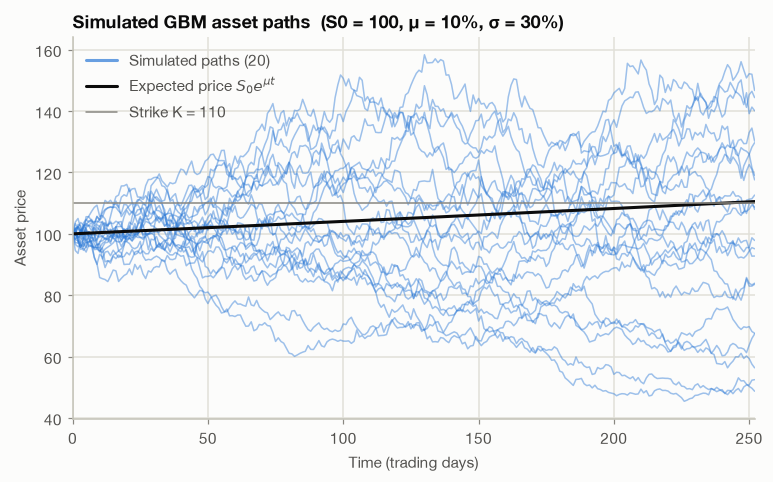

In [3]:
n_steps, n_show = 252, 20
paths = simulate_paths(S0, mu, sigma, T, n_steps, n_show, np.random.default_rng(seed))
t = np.linspace(0, T, n_steps + 1)
days = t * n_steps

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(days, paths.T, color=BLUE, linewidth=1, alpha=0.45)
ax.plot(days, S0 * np.exp(mu * t), color=INK, linewidth=2)
ax.axhline(K, color=MUTED, linewidth=1)

# Legend with line keys (text stays in ink colours)
ax.plot([], [], color=BLUE, linewidth=2, alpha=0.7, label=f"Simulated paths ({n_show})")
ax.plot([], [], color=INK, linewidth=2, label=r"Expected price $S_0 e^{\mu t}$")
ax.plot([], [], color=MUTED, linewidth=1, label=f"Strike K = {K}")
ax.legend(loc="upper left")

ax.set_title(f"Simulated GBM asset paths  (S0 = {S0}, μ = {mu:.0%}, σ = {sigma:.0%})")
ax.set_xlabel("Time (trading days)")
ax.set_ylabel("Asset price")
ax.set_xlim(0, n_steps)
ax.margins(x=0)
fig.savefig("images/asset_prices.png")
plt.show()

## Monte Carlo vs Black-Scholes
Each option is priced with 100,000 risk-neutral paths. The table shows the Monte Carlo estimate with its standard error and 95% confidence interval, next to the analytical price. **Error / SE** measures the gap in standard errors: values within about ±2 are consistent with pure sampling noise.

In [4]:
rng = np.random.default_rng(seed)
rows, mc = [], {}
for option in ("call", "put"):
    price, se = mc_price(S0, K, r, sigma, T, n_paths, option, rng)
    bs = black_scholes_price(S0, K, r, sigma, T, option)
    lo, hi = price - 1.96 * se, price + 1.96 * se
    mc[option] = (price, se)
    rows.append({
        "Option": option.capitalize(),
        "MC price": price,
        "Std error": se,
        "95% CI low": lo,
        "95% CI high": hi,
        "Black-Scholes": bs,
        "Abs error": abs(price - bs),
        "Rel error (%)": 100 * abs(price - bs) / bs,
        "Error / SE": (price - bs) / se,
        "BS in 95% CI": lo <= bs <= hi,
    })

comparison = pd.DataFrame(rows).set_index("Option")
comparison

,MC price,Std error,95% CI low,95% CI high,Black-Scholes,Abs error,Rel error (%),Error / SE,BS in 95% CI
Option,,,,,,,,,
Call,9.2477,0.0600,9.1301,9.3654,9.2400,0.0077,0.0835,0.1285,True
Put,15.9650,0.0540,15.8592,16.0707,15.9890,0.0241,0.1505,-0.4459,True


### Put-call parity
Put-call parity, $C - P = S_0 - K e^{-rT}$, holds exactly for the Black-Scholes prices. The call and put estimates above come from independent draws, so the Monte Carlo gap $\hat C - \hat P$ has standard error $\sqrt{\text{SE}_C^2 + \text{SE}_P^2}$ and should match the parity value to within about two of those.

In [5]:
parity = S0 - K * np.exp(-r * T)
bs_gap = black_scholes_price(S0, K, r, sigma, T, "call") - black_scholes_price(S0, K, r, sigma, T, "put")
(c, se_c), (p, se_p) = mc["call"], mc["put"]
mc_gap, mc_gap_se = c - p, np.hypot(se_c, se_p)

pd.DataFrame(
    {
        "C - P": [bs_gap, mc_gap],
        "S0 - K e^(-rT)": [parity, parity],
        "Difference": [round(bs_gap - parity, 12) + 0.0, mc_gap - parity],
        "Difference / SE": [np.nan, (mc_gap - parity) / mc_gap_se],
    },
    index=["Black-Scholes", "Monte Carlo"],
)

,C - P,S0 - K e^(-rT),Difference,Difference / SE
Black-Scholes,-6.7490,-6.7490,0.0000,NaN
Monte Carlo,-6.7172,-6.7490,0.0318,0.3937


## Convergence
How quickly does the Monte Carlo estimate settle on the Black-Scholes price? The left panels show the estimate and its 95% confidence band as the number of paths grows from $10^2$ to $10^6$. The band narrows steadily around the analytical price. A 95% band should miss about 1 time in 20, so an occasional miss is expected. At very small $n$ the band is also less reliable: the payoff distribution is heavily skewed (most paths finish out of the money), and with few paths the normal approximation behind the band is poor.

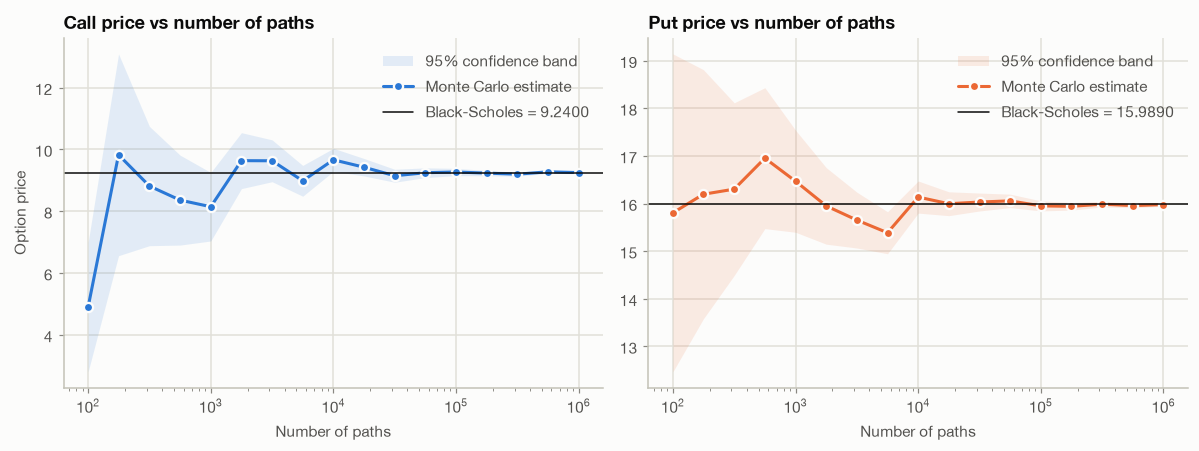

In [6]:
n_grid = np.unique(np.logspace(2, 6, 17).astype(int))
OPTIONS = {"call": BLUE, "put": ORANGE}

rng = np.random.default_rng(seed)
conv = {opt: np.array([mc_price(S0, K, r, sigma, T, n, opt, rng) for n in n_grid]) for opt in OPTIONS}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
for ax, (opt, color) in zip(axes, OPTIONS.items()):
    est, se = conv[opt][:, 0], conv[opt][:, 1]
    bs = black_scholes_price(S0, K, r, sigma, T, opt)
    ax.fill_between(n_grid, est - 1.96 * se, est + 1.96 * se, color=color, alpha=0.12, linewidth=0, label="95% confidence band")
    ax.plot(n_grid, est, color=color, marker="o", markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5, label="Monte Carlo estimate")
    ax.axhline(bs, color=INK, linewidth=1, label=f"Black-Scholes = {bs:.4f}")
    ax.set_xscale("log")
    ax.set_title(f"{opt.capitalize()} price vs number of paths")
    ax.set_xlabel("Number of paths")
    ax.legend(loc="upper right")
axes[0].set_ylabel("Option price")
fig.tight_layout()
plt.show()

### Error rate
A single run's error is noisy, so to measure the convergence rate each estimate is repeated 20 times at every path count. The root-mean-square error (RMSE) against Black-Scholes is then compared with the theoretical $1/\sqrt{n}$ rate. On log-log axes, $1/\sqrt{n}$ is a straight line with slope $-\tfrac{1}{2}$.

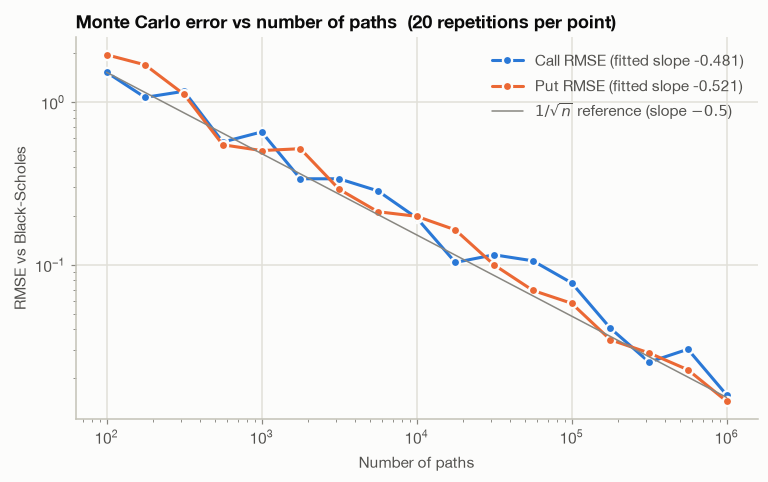

In [7]:
n_reps = 20
rng = np.random.default_rng(seed + 1)
rmse = {}
for opt in OPTIONS:
    bs = black_scholes_price(S0, K, r, sigma, T, opt)
    errs = np.array([[mc_price(S0, K, r, sigma, T, n, opt, rng)[0] - bs for _ in range(n_reps)] for n in n_grid])
    rmse[opt] = np.sqrt((errs**2).mean(axis=1))

fig, ax = plt.subplots(figsize=(8, 4.5))
for opt, color in OPTIONS.items():
    slope = np.polyfit(np.log(n_grid), np.log(rmse[opt]), 1)[0]
    ax.plot(n_grid, rmse[opt], color=color, marker="o", markersize=6, markeredgecolor=SURFACE,
            markeredgewidth=1.5, label=f"{opt.capitalize()} RMSE (fitted slope {slope:.3f})")
# 1/sqrt(n) reference, anchored to the call's RMSE at the smallest n
ref = rmse["call"][0] * np.sqrt(n_grid[0] / n_grid)
ax.plot(n_grid, ref, color=MUTED, linewidth=1, label=r"$1/\sqrt{n}$ reference (slope $-0.5$)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title(f"Monte Carlo error vs number of paths  ({n_reps} repetitions per point)")
ax.set_xlabel("Number of paths")
ax.set_ylabel("RMSE vs Black-Scholes")
ax.legend(loc="upper right")
fig.savefig("images/convergence.png")
plt.show()

## Sweeps across strike and volatility
The comparison above uses a single strike and volatility. Here both are varied, one at a time with the other parameters held at their base values, and each point is priced with 100,000 paths. In the price panels the Monte Carlo estimates (dots) sit on the Black-Scholes curves (lines). Price differences are too small to see at that scale, so the panels below show the error in standard errors. About 95% of points should fall inside the shaded $\pm 1.96$ band, so with 26 points in the strike panel and 22 in the volatility panel, one or two just outside it is expected.

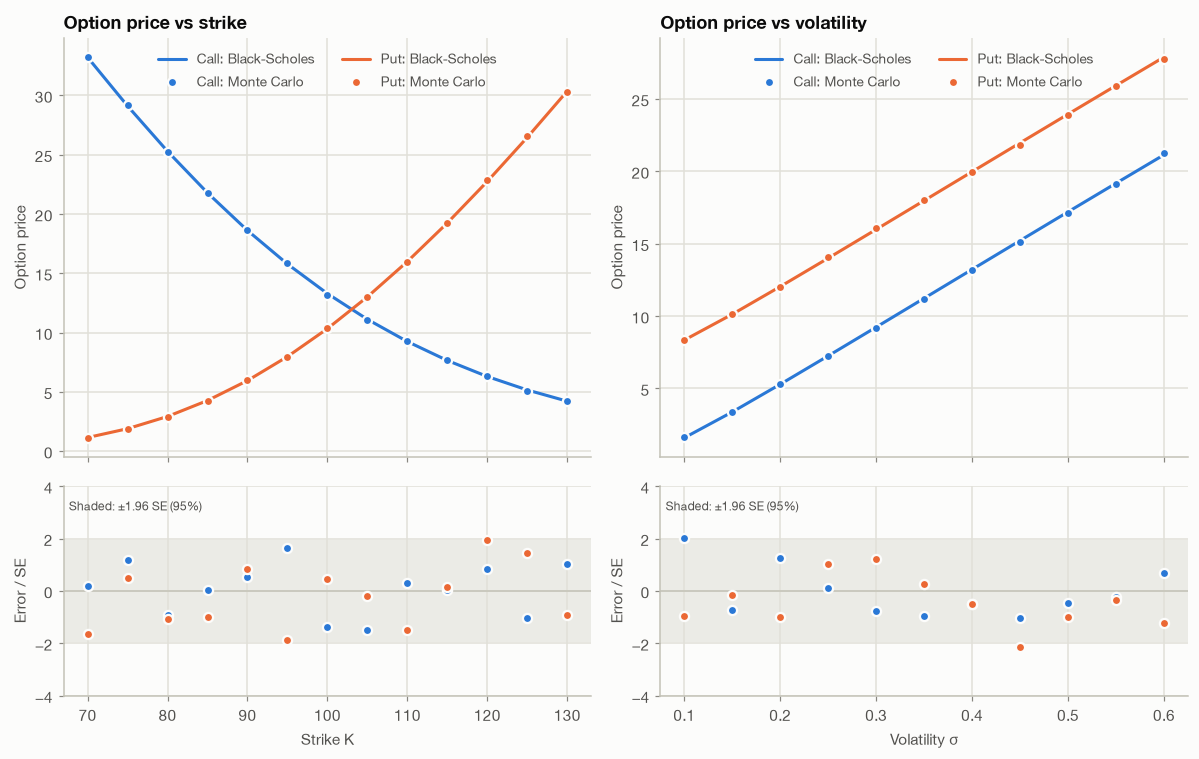

,Points,Inside ±1.96 SE,Max |Error / SE|,Max abs error
Strike K,26,26,1.9456,0.1240
Volatility σ,22,20,2.1273,0.1520


In [8]:
strikes = np.arange(70, 131, 5)
sigmas = np.round(np.arange(0.10, 0.61, 0.05), 2)
rng = np.random.default_rng(seed + 2)

def sweep(values, make_args):
    rows = []
    for v in values:
        args = make_args(v)
        for opt in OPTIONS:
            price, se = mc_price(*args, n_paths, opt, rng)
            bs = black_scholes_price(*args, opt)
            rows.append({"value": v, "option": opt, "mc": price, "se": se, "bs": bs, "z": (price - bs) / se})
    return pd.DataFrame(rows)

sweeps = {
    "Strike K": sweep(strikes, lambda k: (S0, k, r, sigma, T)),
    "Volatility σ": sweep(sigmas, lambda s: (S0, K, r, s, T)),
}

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex="col", gridspec_kw={"height_ratios": [2, 1]})
for col, (label, df) in enumerate(sweeps.items()):
    top, bottom = axes[0, col], axes[1, col]
    bottom.axhspan(-1.96, 1.96, color=GRID, alpha=0.6, linewidth=0)
    bottom.axhline(0, color=AXIS, linewidth=1)
    for opt, color in OPTIONS.items():
        d = df[df.option == opt]
        top.plot(d.value, d.bs, color=color, linewidth=2, label=f"{opt.capitalize()}: Black-Scholes")
        top.plot(d.value, d.mc, linestyle="none", marker="o", markersize=6, color=color,
                 markeredgecolor=SURFACE, markeredgewidth=1.5, label=f"{opt.capitalize()}: Monte Carlo")
        bottom.plot(d.value, d.z, linestyle="none", marker="o", markersize=6, color=color,
                    markeredgecolor=SURFACE, markeredgewidth=1.5)
    top.set_title(f"Option price vs {label.split()[0].lower()}")
    top.set_ylabel("Option price")
    top.legend(loc="upper center", ncol=2, fontsize=9)
    bottom.set_ylabel("Error / SE")
    bottom.set_xlabel(label)
    bottom.set_ylim(-4, 4)
    bottom.text(0.01, 0.94, "Shaded: ±1.96 SE (95%)", transform=bottom.transAxes, color=INK_2, fontsize=8, va="top")
fig.tight_layout()
plt.show()

summary = pd.DataFrame({
    label: {
        "Points": len(df),
        "Inside ±1.96 SE": int((df.z.abs() <= 1.96).sum()),
        "Max |Error / SE|": df.z.abs().max(),
        "Max abs error": (df.mc - df.bs).abs().max(),
    }
    for label, df in sweeps.items()
}).T.astype({"Points": int, "Inside ±1.96 SE": int})
summary